# CNN – Fruit and Vegetable Classification

## 1. Project Description

### Purpose

The purpose of this project is to build and train a Convolutional Neural Network (CNN) to classify images of nine different fruits and vegetables.

We aim to evaluate the model's classification performance and compare the results with the group's baseline model, which uses Logistic Regression.

### Method

We use the group's existing image dataset and predefined training, validation, and test splits to ensure a consistent evaluation.

The CNN learns visual features directly from the images, such as colors, shapes, and textures, rather than relying on manually extracted features.

We train the model on the training set, monitor its performance using the validation set, and evaluate its final performance on the test set using accuracy, macro-F1 score, and a confusion matrix.

## 2. Preparation

### 2.1 Import Libraries and Functions

We begin by importing the required Python libraries and shared functions from the group project.

The load_image() function is used to load and preprocess images, while evaluate_predictions() is used to evaluate model performance.

Reusing these functions helps maintain consistency across the group's models and reduces duplicated code.

In [ ]:

# Standard Python libraries
import sys                       # Access Python settings and module paths
import random
from pathlib import Path        # Work with file and folder paths

# Data analysis and visualization
import numpy as np
import pandas as pd             # Load and analyze datasets
import matplotlib.pyplot as plt # Create plots and visualize images

# PyTorch - Deep Learning
import torch                    # Main PyTorch library
import torch.nn as nn           # Neural network layers and functions
import torch.optim as optim     # Optimization algorithms
from torch.utils.data import Dataset, DataLoader  # Handle image datasets and batches

# Find the project's root directory
project_root = Path.cwd().resolve()

# Move one level up if the notebook runs from the notebooks folder
if project_root.name == "notebooks":
    project_root = project_root.parent

# Add the project directory to Python's module search path
sys.path.insert(0, str(project_root))

# Import shared functions from the group project
from src.preprocess import load_image
from src.evaluate import evaluate_predictions

# Verify the environment
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Project directory:", project_root)
print("All imports successful!")


Python version: 3.14.3
PyTorch version: 2.15.0+cpu
Project directory: C:\Users\PC\Documents\group-project
All imports successful!


## 3. CNN Implementation 

### 3.1 Load the existing train, validation and test split

We use the group's existing dataset split so that the CNN and baseline model can be evaluated on the same test images.

The CSV file contains image paths, target classes, and dataset split assignments.

Before loading the images, we inspect the dataset to verify the number of images in each split and examine the class distribution. This helps us identify potential class imbalances that could affect model performance.

In [2]:

# Load the existing dataset split
csv_path = project_root / "data" / "dataset_split.csv"
df = pd.read_csv(csv_path)

# Display the first five rows
display(df.head())

# Check the number of images in each split
print("\nImages per split:")
print(df["split"].value_counts())

# Check the available classes
print("\nClasses:")
print(sorted(df["target_class"].unique()))

# Check the total number of images
print("\nTotal images:", len(df))

# NEW: Check the class distribution within each split
# This helps identify potential class imbalances in training, validation and test data
print("\nClass distribution per split:")
print(pd.crosstab(df["target_class"], df["split"]))


,image_path,target_class,split
0,data/raw_images/fuji_apple/fuji_apple_002.jpg,apple,test
1,data/raw_images/fuji_apple/fuji_apple_023.jpg,apple,test
2,data/raw_images/fuji_apple/fuji_apple_046.jpg,apple,test
3,data/raw_images/fuji_apple/fuji_apple_053.jpg,apple,test
4,data/raw_images/fuji_apple/fuji_apple_061.jpg,apple,test



Images per split:
split
train         1603
test           200
validation     200
Name: count, dtype: int64

Classes:
['apple', 'honneydew_melon', 'kiwi', 'nectarine', 'onion', 'plum', 'potato', 'spanish_pear', 'watermelon']

Total images: 2003

Class distribution per split:
split            test  train  validation
target_class                            
apple              36    294          37
honneydew_melon    14    117          14
kiwi               15    140          16
nectarine          25    198          24
onion               8     60           7
plum               27    211          26
potato             39    305          39
spanish_pear       16    126          17
watermelon         20    152          20


### 3.2 Load and preprocess images

We use the group's existing `load_image()` function to load and preprocess the images.

Before preparing the dataset for CNN training, we visualize six randomly selected training images to verify that they are loaded correctly and match their assigned labels.

We also inspect the dimensions and pixel value range of one loaded image to check its format.

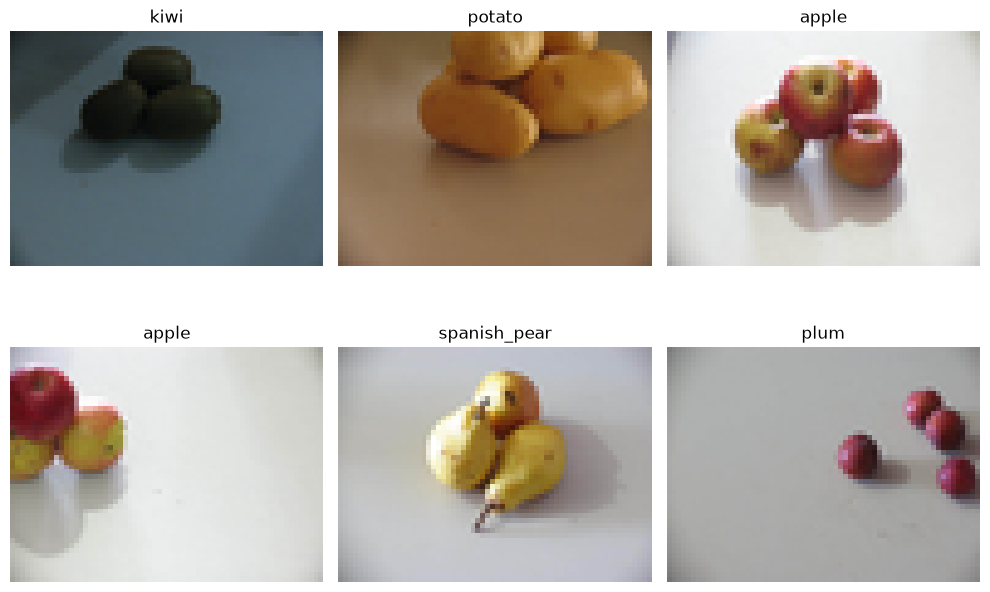

Image shape: (48, 64, 3)
Pixel range: 0.0627451 to 0.8666667


In [3]:

# Select six images from the training dataset
train_df = df[df["split"] == "train"]
sample = train_df.sample(n=6, random_state=42)

# Display the images in a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = project_root / row["image_path"]
    image = load_image(image_path)

    ax.imshow(image)
    ax.set_title(row["target_class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Check image dimensions and pixel values
print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())


#### 3.2.1 Label encoding

We convert the fruit and vegetable class names into numerical labels (0–8), as PyTorch's classification loss function requires integer class labels.

The same class mapping is used for the training, validation, and test datasets to ensure consistent label encoding.

In [4]:

# Get the unique class names from the training dataset and sort them alphabetically
class_names = sorted(train_df["target_class"].unique())

# Create a dictionary that maps each class name to a numerical label
# enumerate() assigns an index starting from 0 to each class name
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# Display the number of classes and their numerical labels
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_idx)


Number of classes: 9
Class mapping: {'apple': 0, 'honneydew_melon': 1, 'kiwi': 2, 'nectarine': 3, 'onion': 4, 'plum': 5, 'potato': 6, 'spanish_pear': 7, 'watermelon': 8}


#### 3.2.2 Create a PyTorch Dataset

We create a custom PyTorch Dataset using the group's existing `load_image()` function.

Each image is loaded and converted into a PyTorch tensor with the required dimensions (channels, height, width). The image is then paired with its corresponding numerical class label.

The Dataset class allows images and labels to be accessed individually during training and evaluation.

In [5]:

# Create a custom PyTorch Dataset class
class FruitDataset(Dataset):

    # Initialize the dataset with image information and class mapping
    def __init__(self, dataframe, project_root, class_to_idx):
        self.dataframe = dataframe.reset_index(drop=True)
        self.project_root = project_root
        self.class_to_idx = class_to_idx

    # Return the total number of images in the dataset
    def __len__(self):
        return len(self.dataframe)

    # Load and return one image and its corresponding label
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Load the image using the group's existing function
        image_path = self.project_root / row["image_path"]
        image = load_image(image_path)

        # Convert the NumPy image into a PyTorch tensor
        # Change dimensions from (height, width, channels)
        # to (channels, height, width)
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Convert the class name into its numerical label
        label = self.class_to_idx[row["target_class"]]

        # Convert the label into a tensor of integer type
        label = torch.tensor(label, dtype=torch.long)

        # Return the image tensor and its label
        return image, label


#### 3.2.3 Create DataLoaders

We create training and validation datasets using our custom `FruitDataset` class.

PyTorch DataLoaders divide the images into batches of 32, allowing the model to process multiple images at a time.

The training data is shuffled to vary the order of images between epochs, while the validation data is kept in a fixed order for consistent evaluation.

The test dataset is reserved for the final model evaluation.

In [6]:

# Select validation images using the group's existing dataset split
val_df = df[df["split"] == "validation"]

# Create training and validation datasets
train_dataset = FruitDataset(train_df, project_root, class_to_idx)
val_dataset = FruitDataset(val_df, project_root, class_to_idx)

# Create DataLoaders that process 32 images per batch
# Shuffle training data to vary the order between epochs
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Keep validation data in a fixed order
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Display the number of images in each dataset
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 1603
Validation images: 200


### 3.3 Build the CNN model

We build a Convolutional Neural Network (CNN) using PyTorch to classify images into nine fruit and vegetable classes.

The model consists of two convolutional layers that extract visual features from the images. Each convolutional layer is followed by a ReLU activation function and max pooling, which reduces the spatial dimensions of the feature maps.

The extracted features are flattened and passed through fully connected layers to produce a prediction score for each class.

The model outputs nine scores (logits), which are used during training to calculate the classification loss.

We also set a fixed random seed before initializing the CNN to make our training results more reproducible and allow fairer comparisons between different model settings.

In [ ]:
# Set a fixed random seed for reproducibility
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Set the seed for CUDA GPUs if available
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

print("Random seed:", seed)

Random seed: 42


In [13]:

# Define a Convolutional Neural Network for image classification
class FruitCNN(nn.Module):

    # Initialize the model with the number of output classes
    def __init__(self, num_classes=9):
        super().__init__()

        # Extract visual features from the input images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 3 input channels, 16 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2),                            # Reduce height and width by half

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 input channels, 32 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2)                             # Reduce height and width by half
        )

        # Classify the extracted image features
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # Convert feature maps into a one-dimensional vector
            nn.Linear(32 * 12 * 16, 128), # Connect extracted features to 128 neurons
            nn.ReLU(),                     # Introduce non-linearity
            nn.Linear(128, num_classes)    # Output one score for each class
        )

    # Define how data moves through the network
    def forward(self, x):
        x = self.features(x)      # Extract visual features
        x = self.classifier(x)    # Calculate class scores
        return x                 # Return the logits

# Create the CNN model using the number of available classes
model = FruitCNN(num_classes=len(class_names))

# Display the model architecture
print(model)


FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)


#### 3.3.1 Verify Model Input and Output Dimensions

Before training, we verify that the CNN accepts batches of preprocessed images and produces one prediction score per class. This helps detect potential dimension mismatches.

In [8]:
# Get one batch of images and labels
images, labels = next(iter(train_loader))

# Display the batch dimensions and data type
print("Batch shape:", images.shape)
print("Image dtype:", images.dtype)

# Pass the batch through the CNN without calculating gradients
with torch.no_grad():
    outputs = model(images)

# Check that the model produces one score per class
print("Output shape:", outputs.shape)

Batch shape: torch.Size([32, 3, 48, 64])
Image dtype: torch.float32
Output shape: torch.Size([32, 9])


### 3.4 Configure model training

We use CrossEntropyLoss to measure the difference between the model's predicted class scores and the correct class labels.

The Adam optimizer updates the model's weights during training to minimize the loss. We use a learning rate of 0.001, which controls the size of the optimization steps.

The model automatically selects an available GPU (CUDA for NVIDIA or MPS for Apple Silicon). If GPU acceleration is unavailable, training runs on the CPU.

In [14]:
# Select the best available device for training
if torch.cuda.is_available():
    device = torch.device("cuda")  # NVIDIA GPU, commonly used on Windows

elif torch.backends.mps.is_available():
    device = torch.device("mps")   # Apple Silicon GPU (Mac)

else:
    device = torch.device("cpu")   # Fallback for computers without supported GPU acceleration

# Move the CNN model to the selected device
model = model.to(device)

# Define the loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Define the Adam optimizer with a learning rate of 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Display the training configuration
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam


### 3.5 Train the CNN model

We train the CNN for 10 epochs using the training dataset. During each epoch, the model updates its weights using the Adam optimizer to minimize the classification loss.

After each epoch, we evaluate the model on the validation dataset without updating its weights.

We record training and validation loss and accuracy to monitor the model's learning progress and identify potential overfitting.

We also save the model with the lowest validation loss to make sure we keep the best-performing model during training.

In [15]:
# Define the number of training epochs
num_epochs = 10

# Create lists to store training and validation metrics
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Track the best validation loss and corresponding epoch
best_val_loss = float("inf")
best_epoch = 0

# Define where to save the best model
best_model_path = project_root / "best_cnn_model.pth"

# Repeat training and validation for each epoch
for epoch in range(num_epochs):

    # --- TRAINING ---
    model.train()  # Set the model to training mode
    running_loss = 0
    correct = 0
    total = 0

    # Process one batch of training images at a time
    for images, labels in train_loader:
        images = images.to(device)  # Move images to GPU or CPU
        labels = labels.to(device)  # Move labels to the same device

        optimizer.zero_grad()  # Clear gradients from the previous batch

        outputs = model(images)  # Calculate prediction scores
        loss = criterion(outputs, labels)  # Calculate classification loss

        loss.backward()  # Calculate gradients
        optimizer.step()  # Update model weights

        # Accumulate loss, weighted by the number of images in the batch
        running_loss += loss.item() * images.size(0)

        # Count correct predictions
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Calculate average training loss and accuracy
    train_loss = running_loss / total
    train_accuracy = correct / total

    # --- VALIDATION ---
    model.eval()  # Set the model to evaluation mode
    running_val_loss = 0
    val_correct = 0
    val_total = 0

    # Disable gradient calculations during validation
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            # Accumulate validation loss
            running_val_loss += loss.item() * images.size(0)

            # Count correct validation predictions
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # Calculate average validation loss and accuracy
    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # Save metrics for visualization
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Save the model if validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_model_path)

    # Display results after each epoch
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Val accuracy: {val_accuracy:.2%}"
    )

# Display the best model results
print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model saved to: {best_model_path}")

Epoch 1/10 | Train loss: 1.6284 | Val loss: 1.1877 | Train accuracy: 40.36% | Val accuracy: 62.00%
Epoch 2/10 | Train loss: 0.7976 | Val loss: 0.5808 | Train accuracy: 72.24% | Val accuracy: 79.50%
Epoch 3/10 | Train loss: 0.4683 | Val loss: 0.4659 | Train accuracy: 83.97% | Val accuracy: 82.50%
Epoch 4/10 | Train loss: 0.3426 | Val loss: 0.3637 | Train accuracy: 87.71% | Val accuracy: 87.50%
Epoch 5/10 | Train loss: 0.2940 | Val loss: 0.3948 | Train accuracy: 89.46% | Val accuracy: 84.00%
Epoch 6/10 | Train loss: 0.1999 | Val loss: 0.2838 | Train accuracy: 93.51% | Val accuracy: 90.50%
Epoch 7/10 | Train loss: 0.1828 | Val loss: 0.2121 | Train accuracy: 94.45% | Val accuracy: 93.50%
Epoch 8/10 | Train loss: 0.1238 | Val loss: 0.2288 | Train accuracy: 96.38% | Val accuracy: 90.50%
Epoch 9/10 | Train loss: 0.1109 | Val loss: 0.2695 | Train accuracy: 96.57% | Val accuracy: 87.50%
Epoch 10/10 | Train loss: 0.1618 | Val loss: 0.1536 | Train accuracy: 95.63% | Val accuracy: 94.00%

Best epo

### 3.6 Visualize training results

We visualize training and validation loss and accuracy across the 10 epochs.

These plots help us monitor the CNN's learning progress and identify potential signs of overfitting.

By comparing training and validation performance, we can assess how well the model generalizes to unseen validation images.

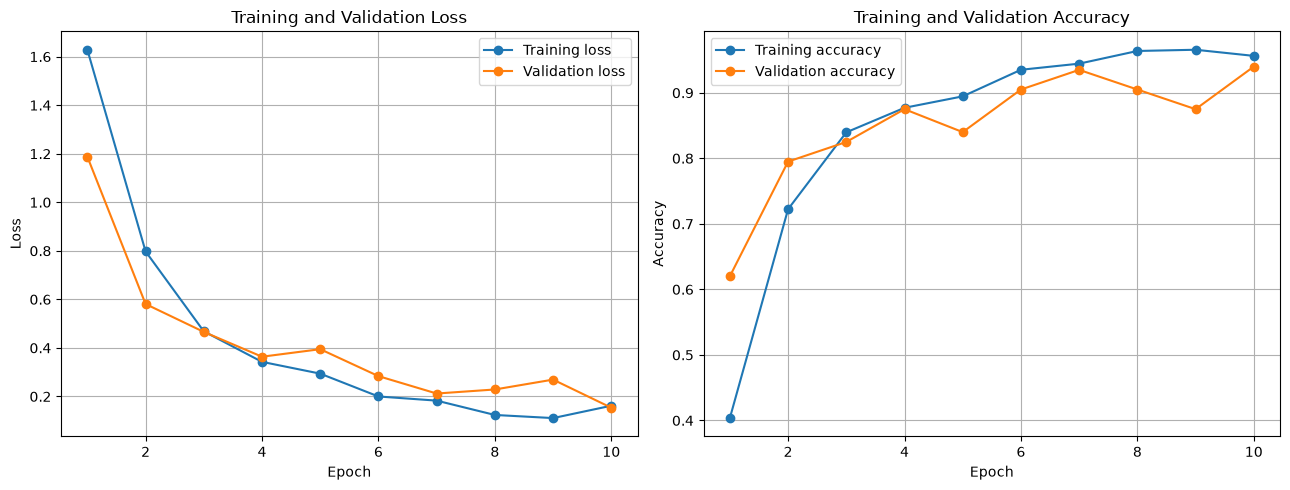

In [16]:

# Create epoch numbers for the x-axis
epochs = range(1, num_epochs + 1)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot training and validation loss
axes[0].plot(epochs, train_losses, label="Training loss", marker="o")
axes[0].plot(epochs, val_losses, label="Validation loss", marker="o")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation accuracy
axes[1].plot(epochs, train_accuracies, label="Training accuracy", marker="o")
axes[1].plot(epochs, val_accuracies, label="Validation accuracy", marker="o")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# Adjust layout and display the plots
plt.tight_layout()
plt.show()


#### 3.6.1 Analysis of training results

Both training and validation loss decrease overall, showing that the CNN is learning to recognize the different fruit classes.

Training accuracy increases from 40.36% to 95.63%, while validation accuracy improves from 62% to 94%.

The validation curves fluctuate slightly during the later epochs, but there are no clear signs of serious overfitting.

The lowest validation loss (0.1536) is reached at epoch 10, and this model is saved for further evaluation.

Overall, the results show that the CNN performs well on the validation dataset.

### 3.7 Evaluate the CNN on validation data

We evaluate the best saved CNN model using the validation dataset.

We compare the predicted labels with the actual labels to identify which fruit and vegetable classes the model recognizes correctly and which classes it confuses.

The test dataset is reserved for final evaluation.

In [17]:
# Load the best model saved during training
best_model = FruitCNN(num_classes=len(class_names)).to(device)
best_model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

# Set the model to evaluation mode
best_model.eval()

# Create lists to store actual and predicted labels
y_true = []
y_pred = []

# Evaluate the model without updating its weights
with torch.no_grad():
    for images, labels in val_loader:

        # Move images to the selected device
        images = images.to(device)

        # Predict the fruit and vegetable classes
        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        # Collect actual labels and predictions
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Display the number of evaluated images and correct predictions
correct_predictions = sum(
    actual == predicted for actual, predicted in zip(y_true, y_pred)
)

print("Validation images evaluated:", len(y_true))
print("Correct predictions:", correct_predictions)
print(f"Validation accuracy: {correct_predictions / len(y_true):.2%}")

Validation images evaluated: 200
Correct predictions: 188
Validation accuracy: 94.00%


#### 3.7.1 Confusion Matrix

We use a confusion matrix to visualize how well the CNN classifies each fruit and vegetable class.

The diagonal shows correct predictions, while values outside the diagonal show which classes the model confuses.

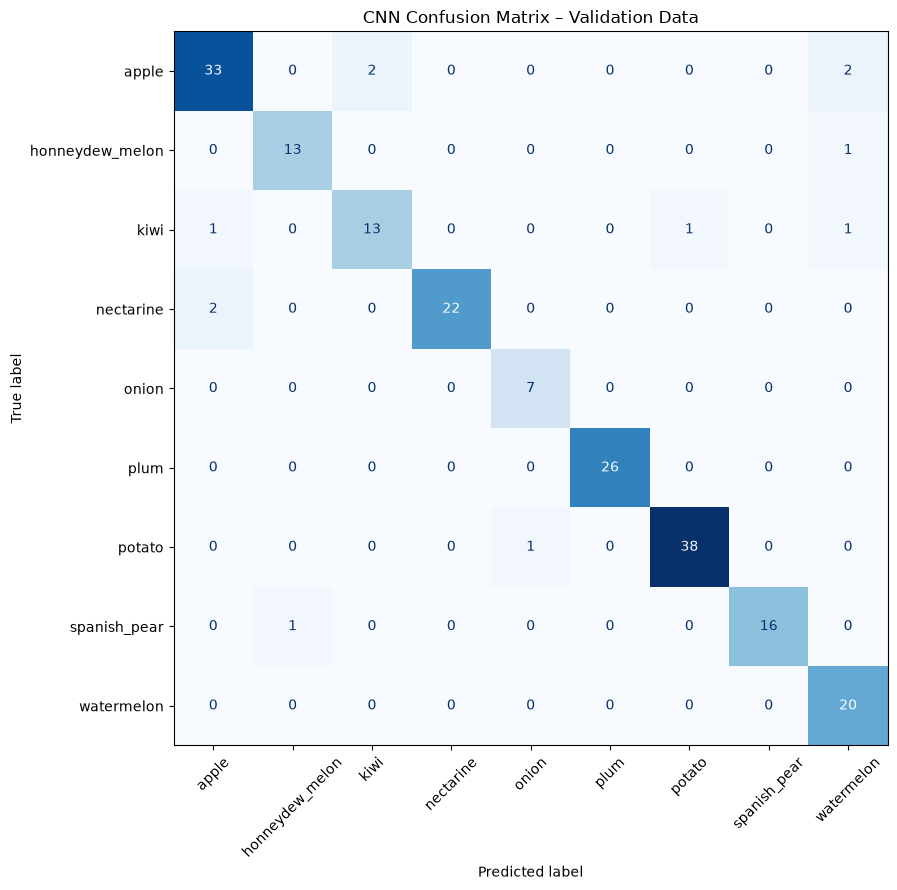

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix using actual and predicted labels
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Visualize the confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN Confusion Matrix – Validation Data")

plt.tight_layout()
plt.show()

#### 3.7.2 Classification Report

We use a classification report to evaluate precision, recall and F1-score for each class.

This gives us a more detailed understanding of the CNN's performance, especially since the number of images differs between classes.

In [19]:
from sklearn.metrics import classification_report

# Generate classification metrics for all fruit and vegetable classes
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
)

# Display precision, recall, F1-score and support
print(report)

                 precision    recall  f1-score   support

          apple       0.92      0.89      0.90        37
honneydew_melon       0.93      0.93      0.93        14
           kiwi       0.87      0.81      0.84        16
      nectarine       1.00      0.92      0.96        24
          onion       0.88      1.00      0.93         7
           plum       1.00      1.00      1.00        26
         potato       0.97      0.97      0.97        39
   spanish_pear       1.00      0.94      0.97        17
     watermelon       0.83      1.00      0.91        20

       accuracy                           0.94       200
      macro avg       0.93      0.94      0.93       200
   weighted avg       0.94      0.94      0.94       200



#### 3.7.3 Analysis of validation results

The CNN correctly classifies 188 out of 200 validation images, achieving an accuracy of 94%.

The classification report shows a macro F1-score of 0.93, indicating good performance across the nine classes.

The confusion matrix shows that plum and watermelon are correctly classified in all cases. Kiwi has the lowest F1-score (0.84), making it the most challenging class for the model.

Some apples are confused with kiwi and watermelon, while two nectarines are classified as apples.

Overall, the CNN performs well on the validation dataset, but there is still room for improvement in distinguishing certain classes.

#### 3.7.4 Visualize Misclassified Images

We visualize the validation images that our CNN classified incorrectly.

For each image, we show the actual class and the predicted class. This helps us understand which fruits and vegetables the model has difficulty distinguishing.

By examining these images, we can identify possible reasons for the classification errors and areas for improvement.

Misclassified images: 12


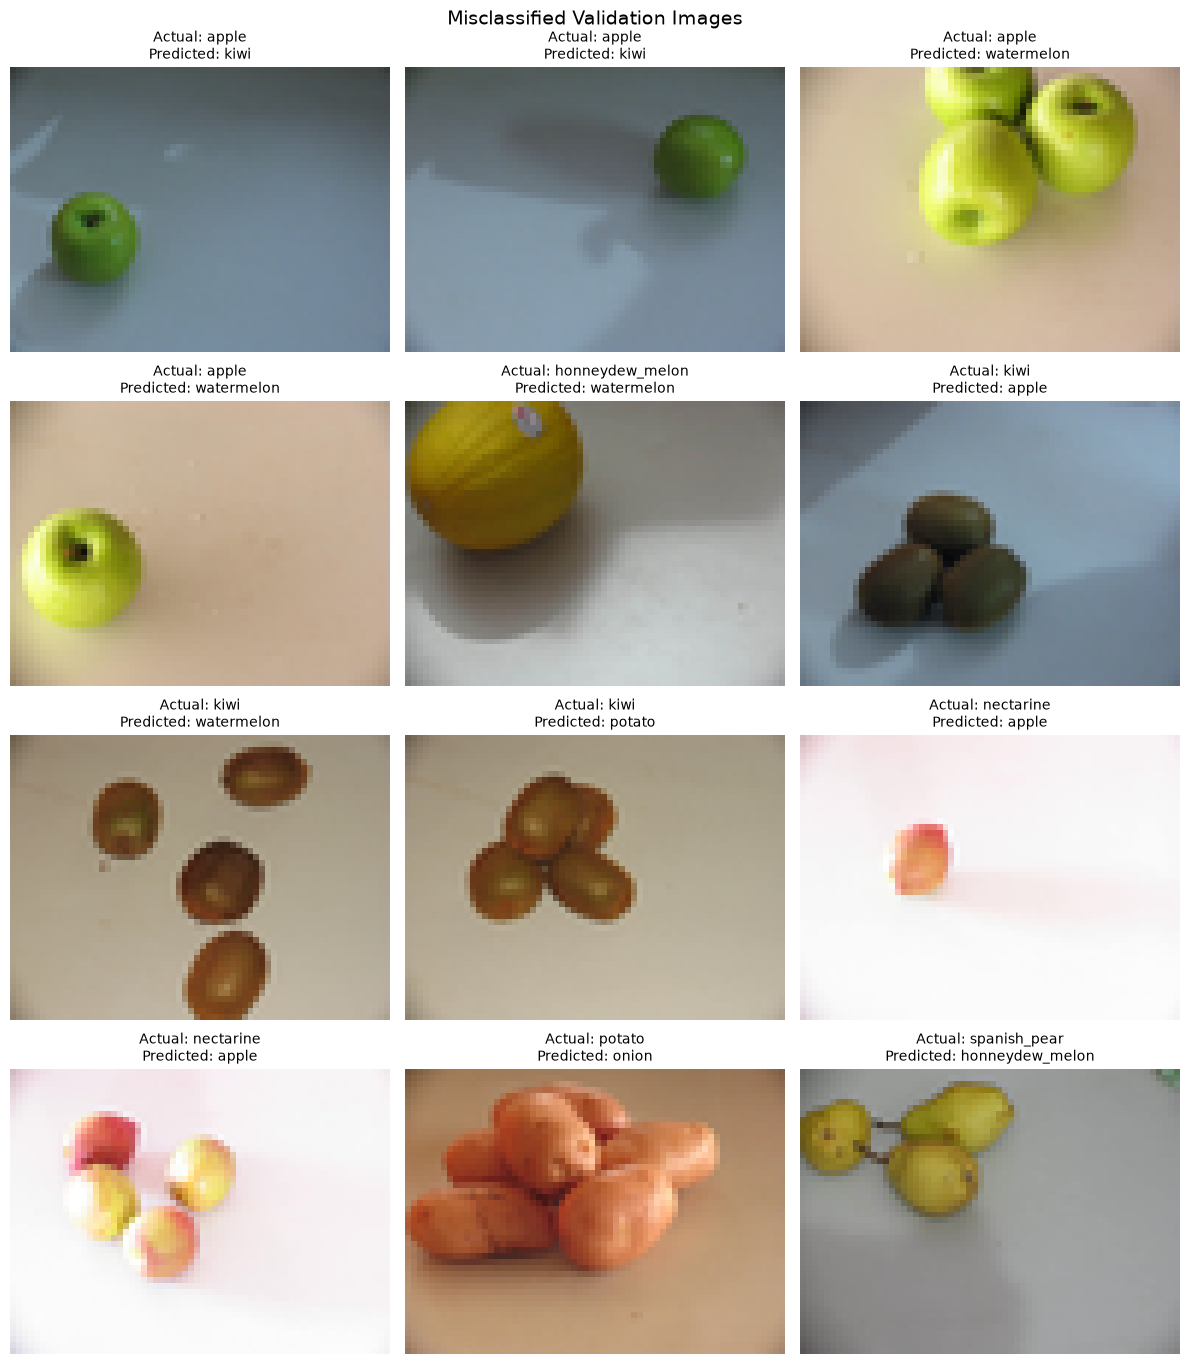

In [20]:
# Find the validation images that were classified incorrectly
incorrect_indices = [
    i for i, (actual, predicted) in enumerate(zip(y_true, y_pred))
    if actual != predicted
]

# Display the total number of incorrect predictions
print("Misclassified images:", len(incorrect_indices))

# Create a grid to display the misclassified images
num_images = len(incorrect_indices)
num_cols = 3
num_rows = (num_images + num_cols - 1) // num_cols

fig, axes = plt.subplots(
    num_rows, num_cols,
    figsize=(12, num_rows * 3.5)
)

# Flatten the axes to simplify image placement
axes = axes.flatten()

# Display each incorrectly classified image
for ax, idx in zip(axes, incorrect_indices):

    # Get the image path from the validation dataset
    row = val_dataset.dataframe.iloc[idx]
    image_path = project_root / row["image_path"]

    # Load the image using the group's existing function
    image = load_image(image_path)

    # Get the actual and predicted class names
    actual_class = class_names[y_true[idx]]
    predicted_class = class_names[y_pred[idx]]

    # Display the image with its actual and predicted labels
    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual_class}\nPredicted: {predicted_class}",
        fontsize=10
    )
    ax.axis("off")

# Hide any unused positions in the grid
for ax in axes[num_images:]:
    ax.axis("off")

plt.suptitle("Misclassified Validation Images", fontsize=14)
plt.tight_layout()
plt.show()

### 3.8 Improve and Compare CNN Models

We investigate whether adding dropout can improve our CNN model.

Dropout randomly disables some neurons during training, which can help reduce overfitting and improve generalization.

We train a second CNN with dropout and compare its validation results with our original model.

We use the same training and validation datasets to make the comparison fair. The test dataset is reserved for final evaluation.

#### 3.8.1 Create a CNN with Dropout

We create a second CNN with the same architecture as our original model, but add a dropout layer with a rate of 0.3.

This means that 30% of the neurons in this layer are randomly disabled during training. We want to investigate whether this improves the model's performance on the validation dataset.

In [21]:
# Define a CNN with dropout
class FruitCNNDropout(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Extract features from images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Classify images with dropout to reduce overfitting
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 12 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    # Define how images pass through the network
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Set the random seed before initializing the new model
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Create the CNN with dropout
dropout_model = FruitCNNDropout(num_classes=len(class_names)).to(device)

# Display the model architecture
print(dropout_model)

FruitCNNDropout(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)


#### 3.8.2 Train the CNN with Dropout

We train the CNN with dropout for 10 epochs using the same training settings as our original model.

During training, we track training and validation loss and accuracy. We save the model with the lowest validation loss to compare it with our original CNN.

The best dropout model is saved separately to preserve the original model.

In [22]:
# Configure training for the dropout model
dropout_criterion = nn.CrossEntropyLoss()
dropout_optimizer = optim.Adam(dropout_model.parameters(), lr=0.001)

dropout_epochs = 10

dropout_train_losses = []
dropout_val_losses = []
dropout_train_accuracies = []
dropout_val_accuracies = []

best_dropout_val_loss = float("inf")
best_dropout_epoch = 0

best_dropout_model_path = project_root / "best_cnn_dropout_model.pth"

# Train the dropout model
for epoch in range(dropout_epochs):

    dropout_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        dropout_optimizer.zero_grad()

        outputs = dropout_model(images)
        loss = dropout_criterion(outputs, labels)

        loss.backward()
        dropout_optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = train_loss / train_total
    epoch_train_accuracy = 100 * train_correct / train_total

    # Evaluate on validation data
    dropout_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = dropout_model(images)
            loss = dropout_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_accuracy = 100 * val_correct / val_total

    # Store training history
    dropout_train_losses.append(epoch_train_loss)
    dropout_val_losses.append(epoch_val_loss)
    dropout_train_accuracies.append(epoch_train_accuracy)
    dropout_val_accuracies.append(epoch_val_accuracy)

    # Save the model with the lowest validation loss
    if epoch_val_loss < best_dropout_val_loss:
        best_dropout_val_loss = epoch_val_loss
        best_dropout_epoch = epoch + 1

        torch.save(
            dropout_model.state_dict(),
            best_dropout_model_path
        )

    print(
        f"Epoch {epoch + 1}/{dropout_epochs} | "
        f"Train loss: {epoch_train_loss:.4f} | "
        f"Val loss: {epoch_val_loss:.4f} | "
        f"Train accuracy: {epoch_train_accuracy:.2f}% | "
        f"Val accuracy: {epoch_val_accuracy:.2f}%"
    )

print(f"\nBest epoch: {best_dropout_epoch}")
print(f"Best validation loss: {best_dropout_val_loss:.4f}")
print(f"Best dropout model saved to: {best_dropout_model_path}")

Epoch 1/10 | Train loss: 1.7246 | Val loss: 1.2866 | Train accuracy: 38.18% | Val accuracy: 53.00%
Epoch 2/10 | Train loss: 1.0005 | Val loss: 0.8675 | Train accuracy: 64.88% | Val accuracy: 67.00%
Epoch 3/10 | Train loss: 0.6802 | Val loss: 0.5363 | Train accuracy: 75.05% | Val accuracy: 84.00%
Epoch 4/10 | Train loss: 0.5000 | Val loss: 0.4785 | Train accuracy: 82.84% | Val accuracy: 84.50%
Epoch 5/10 | Train loss: 0.3834 | Val loss: 0.4282 | Train accuracy: 86.03% | Val accuracy: 84.50%
Epoch 6/10 | Train loss: 0.3405 | Val loss: 0.2523 | Train accuracy: 88.90% | Val accuracy: 93.00%
Epoch 7/10 | Train loss: 0.2622 | Val loss: 0.3439 | Train accuracy: 91.33% | Val accuracy: 86.00%
Epoch 8/10 | Train loss: 0.2451 | Val loss: 0.1661 | Train accuracy: 90.89% | Val accuracy: 95.00%
Epoch 9/10 | Train loss: 0.1896 | Val loss: 0.2126 | Train accuracy: 94.01% | Val accuracy: 91.50%
Epoch 10/10 | Train loss: 0.1684 | Val loss: 0.1900 | Train accuracy: 94.88% | Val accuracy: 93.50%

Best epo

#### 3.8.3 Compare CNN Models

We compare the validation loss and validation accuracy of our original CNN and the CNN with dropout.

Both models were trained for 10 epochs using the same dataset and training settings. The comparison helps us evaluate whether adding dropout improves model performance. 

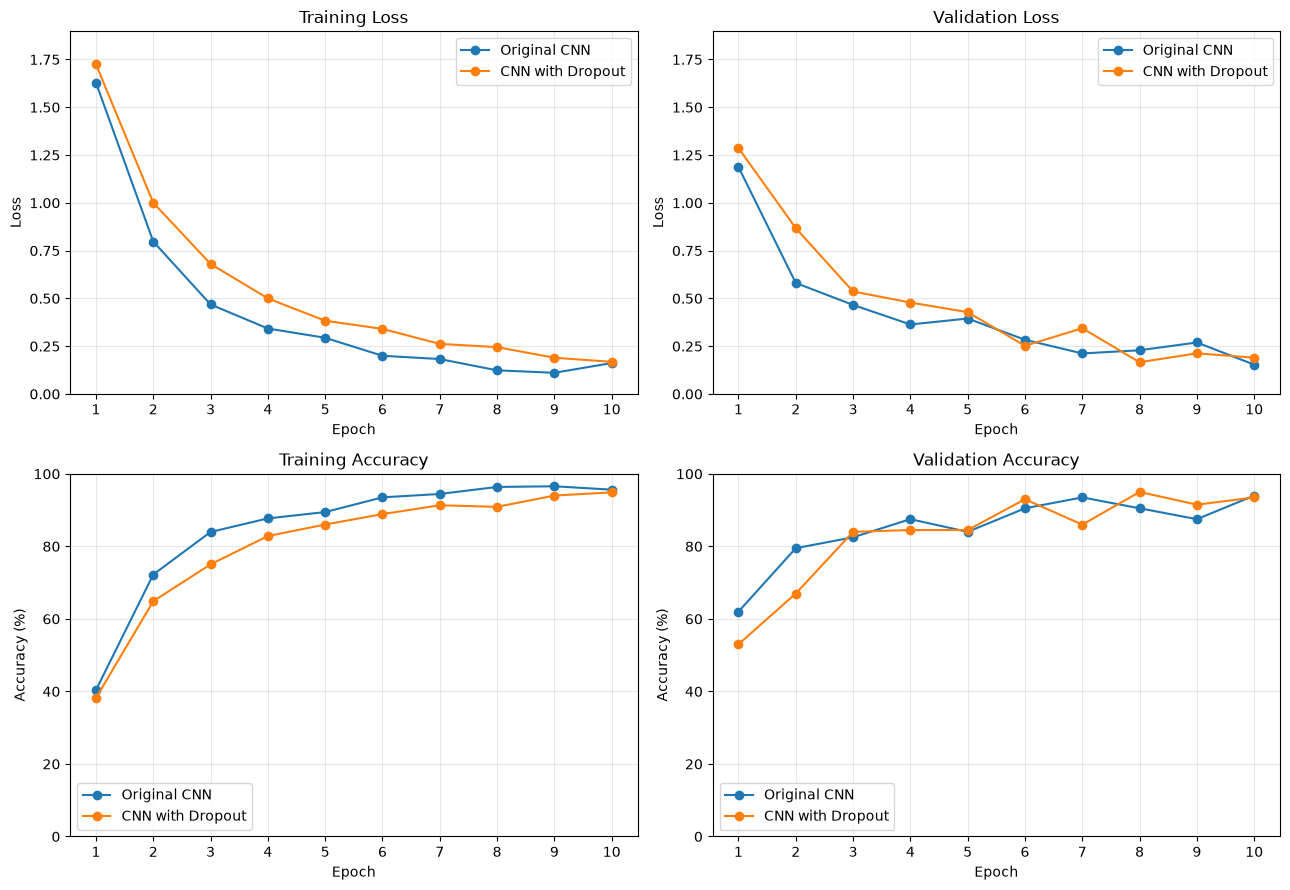

In [26]:
# Compare training and validation performance of both CNN models
epochs_range = range(1, 11)

# Convert accuracy values to percentages when necessary
def to_percent(values):
    return [v * 100 for v in values] if max(values) <= 1 else values

original_train_acc = to_percent(train_accuracies)
original_val_acc = to_percent(val_accuracies)
dropout_train_acc = to_percent(dropout_train_accuracies)
dropout_val_acc = to_percent(dropout_val_accuracies)

# Create four comparison plots
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Training loss
axes[0, 0].plot(
    epochs_range, train_losses,
    marker="o", label="Original CNN"
)
axes[0, 0].plot(
    epochs_range, dropout_train_losses,
    marker="o", label="CNN with Dropout"
)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_ylabel("Loss")

# 2. Validation loss
axes[0, 1].plot(
    epochs_range, val_losses,
    marker="o", label="Original CNN"
)
axes[0, 1].plot(
    epochs_range, dropout_val_losses,
    marker="o", label="CNN with Dropout"
)
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_ylabel("Loss")

# 3. Training accuracy
axes[1, 0].plot(
    epochs_range, original_train_acc,
    marker="o", label="Original CNN"
)
axes[1, 0].plot(
    epochs_range, dropout_train_acc,
    marker="o", label="CNN with Dropout"
)
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_ylabel("Accuracy (%)")

# 4. Validation accuracy
axes[1, 1].plot(
    epochs_range, original_val_acc,
    marker="o", label="Original CNN"
)
axes[1, 1].plot(
    epochs_range, dropout_val_acc,
    marker="o", label="CNN with Dropout"
)
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_ylabel("Accuracy (%)")

# Use the same Y-axis scale for both loss plots
max_loss = max(
    max(train_losses),
    max(val_losses),
    max(dropout_train_losses),
    max(dropout_val_losses)
)

axes[0, 0].set_ylim(0, max_loss * 1.1)
axes[0, 1].set_ylim(0, max_loss * 1.1)

# Use the same Y-axis scale for both accuracy plots
axes[1, 0].set_ylim(0, 100)
axes[1, 1].set_ylim(0, 100)

# Apply consistent formatting to all plots
for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs_range))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 3.8.4 Analysis of Model Comparison

Both models improve during training. Their loss decreases and their accuracy increases, which means they are learning to recognize the different fruits and vegetables.

**Training results:** The original CNN learns faster and performs slightly better on the training images. This is expected because dropout makes training more difficult.

**Validation results:** Both models also perform well on images they have not trained on. The original CNN has a slightly lower validation loss (0.1536 compared to 0.1661). However, the dropout model has a slightly higher accuracy (95% compared to 94%).

This means that the dropout model correctly classifies 190 out of 200 validation images, compared to 188 for the original CNN.

**Overfitting:** Neither model shows clear signs of serious overfitting, since both perform well on training and validation images.

**Conclusion:** Adding dropout did not make a big difference. The original CNN has lower loss, while the dropout model gets two more images correct. We need to compare precision, recall and F1-score before deciding which model performs best overall.

#### 3.8.5 Compare Precision, Recall and F1-score

We compare precision, recall and F1-score for our original CNN and the CNN with dropout.

These metrics help us understand how well each model recognizes the nine different classes.

We use the same validation images for both models to make the comparison fair.

In [28]:
from sklearn.metrics import precision_recall_fscore_support
from IPython.display import display as show_table
import pandas as pd

# Load the best saved original CNN
original_model = FruitCNN(num_classes=len(class_names)).to(device)

original_model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

original_model.eval()

# Load the best saved CNN with dropout
dropout_best_model = FruitCNNDropout(
    num_classes=len(class_names)
).to(device)

dropout_best_model.load_state_dict(
    torch.load(best_dropout_model_path, map_location=device, weights_only=True)
)

dropout_best_model.eval()

# Collect predictions from both models
y_true_compare = []
original_predictions = []
dropout_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        original_outputs = original_model(images)
        dropout_outputs = dropout_best_model(images)

        y_true_compare.extend(labels.cpu().numpy())

        original_predictions.extend(
            original_outputs.argmax(dim=1).cpu().numpy()
        )

        dropout_predictions.extend(
            dropout_outputs.argmax(dim=1).cpu().numpy()
        )

# Calculate precision, recall and F1-score for each class
def get_class_metrics(y_true, y_pred, model_name):

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        zero_division=0
    )

    return pd.DataFrame({
        "Class": class_names,
        f"{model_name} Precision": precision,
        f"{model_name} Recall": recall,
        f"{model_name} F1": f1
    })

# Calculate metrics for the original CNN
original_metrics = get_class_metrics(
    y_true_compare,
    original_predictions,
    "Original"
)

# Calculate metrics for the CNN with dropout
dropout_metrics = get_class_metrics(
    y_true_compare,
    dropout_predictions,
    "Dropout"
)

# Combine the results into one comparison table
comparison_df = original_metrics.merge(
    dropout_metrics,
    on="Class"
)

# Display the comparison table
show_table(comparison_df.round(2))

,Class,Original Precision,Original Recall,Original F1,Dropout Precision,Dropout Recall,Dropout F1
0,apple,0.92,0.89,0.90,0.90,0.95,0.92
1,honneydew_melon,0.93,0.93,0.93,1.00,1.00,1.00
2,kiwi,0.87,0.81,0.84,0.82,0.88,0.85
3,nectarine,1.00,0.92,0.96,0.95,0.88,0.91
4,onion,0.88,1.00,0.93,0.86,0.86,0.86
5,plum,1.00,1.00,1.00,1.00,1.00,1.00
6,potato,0.97,0.97,0.97,0.97,0.97,0.97
7,spanish_pear,1.00,0.94,0.97,1.00,0.94,0.97
8,watermelon,0.83,1.00,0.91,1.00,1.00,1.00


#### 3.8.6 Visualize F1-score Comparison

We compare the F1-scores of both CNN models for each fruit and vegetable class.

A higher F1-score means a better balance between precision and recall. This visualization helps us identify which classes improved or became worse after adding dropout.

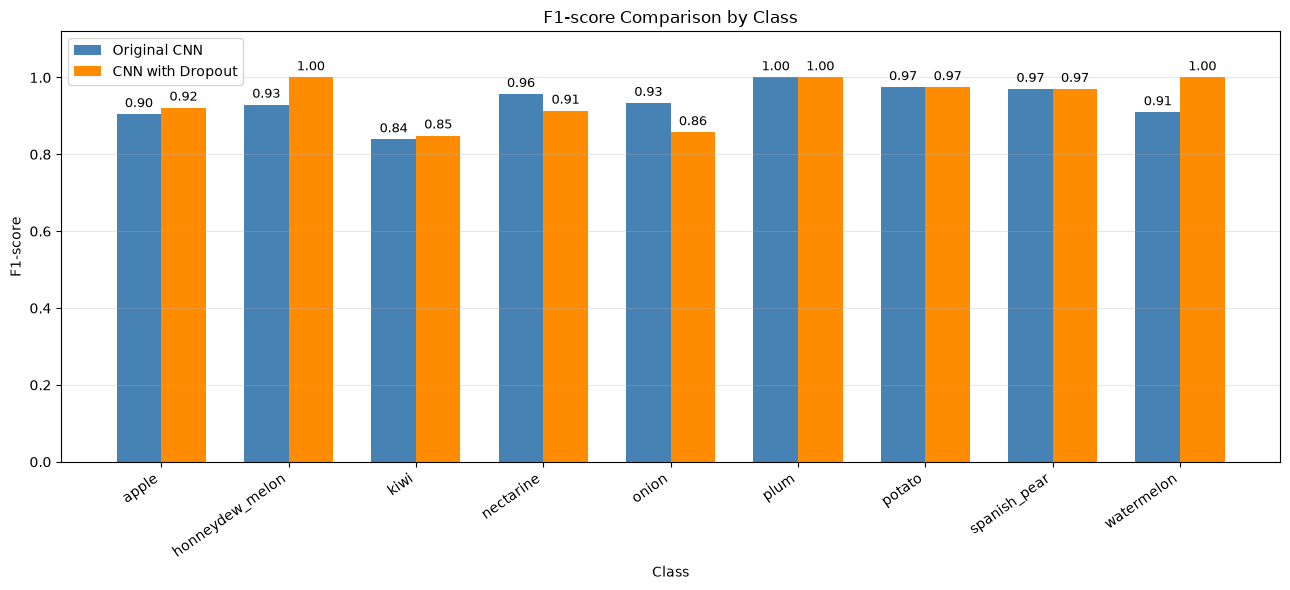

In [29]:
# Compare F1-scores for each class
x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))

# Original CNN
bars_original = ax.bar(
    x - width / 2,
    comparison_df["Original F1"],
    width,
    label="Original CNN",
    color="steelblue"
)

# CNN with Dropout
bars_dropout = ax.bar(
    x + width / 2,
    comparison_df["Dropout F1"],
    width,
    label="CNN with Dropout",
    color="darkorange"
)

# Display F1-score values above each bar
ax.bar_label(bars_original, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(bars_dropout, fmt="%.2f", padding=3, fontsize=9)

# Format the chart
ax.set_title("F1-score Comparison by Class")
ax.set_xlabel("Class")
ax.set_ylabel("F1-score")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=35, ha="right")
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 3.8.7 Analysis and Model Selection

The F1-score comparison shows that both CNN models perform well, but adding dropout affects the classes differently.

The dropout model performs better on apple, honeydew melon, kiwi and watermelon. The biggest improvement is for watermelon, where the F1-score increases from 0.91 to 1.00.

However, the original CNN performs better on nectarine and onion. Both models achieve the same results for plum, potato and spanish pear.

The dropout model also has slightly higher validation accuracy (95% compared to 94%), but the original CNN has lower validation loss.

**Conclusion:** Dropout improves some classes but makes others worse. The overall difference between the models is small, and neither model is clearly better in every way.

We choose the CNN with dropout for final evaluation because it correctly classifies slightly more validation images. However, the difference is small, so we cannot be certain that it will perform better on new data.

#### 3.9.1 Test Evaluation

We evaluate our selected CNN with dropout on the 200 test images.

These images have not been used during training or model selection.

We calculate accuracy, precision, recall and F1-score to measure how well the model performs on unseen images.

In [31]:
from sklearn.metrics import accuracy_score, classification_report

# Select test images from the shared dataset
test_df = df[df["split"] == "test"].reset_index(drop=True)

# Create the test dataset using the same settings as training
test_dataset = FruitDataset(
    test_df,
    project_root,
    class_to_idx
)

# Create the test DataLoader without shuffling
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Load the best saved CNN with dropout
final_model = FruitCNNDropout(
    num_classes=len(class_names)
).to(device)

final_model.load_state_dict(
    torch.load(
        best_dropout_model_path,
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

# Collect predictions on the test images
test_y_true = []
test_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        test_y_true.extend(labels.cpu().numpy())
        test_y_pred.extend(predictions.cpu().numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(test_y_true, test_y_pred)

correct_predictions = sum(
    actual == predicted
    for actual, predicted in zip(test_y_true, test_y_pred)
)

print(f"Test images: {len(test_y_true)}")
print(f"Correct predictions: {correct_predictions}")
print(f"Test accuracy: {test_accuracy:.2%}")

# Display precision, recall and F1-score for each class
print("\nClassification Report:")

print(
    classification_report(
        test_y_true,
        test_y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

Test images: 200
Correct predictions: 197
Test accuracy: 98.50%

Classification Report:
                 precision    recall  f1-score   support

          apple       0.95      0.97      0.96        36
honneydew_melon       1.00      1.00      1.00        14
           kiwi       0.93      0.93      0.93        15
      nectarine       1.00      0.96      0.98        25
          onion       1.00      1.00      1.00         8
           plum       1.00      1.00      1.00        27
         potato       1.00      1.00      1.00        39
   spanish_pear       1.00      1.00      1.00        16
     watermelon       1.00      1.00      1.00        20

       accuracy                           0.98       200
      macro avg       0.99      0.99      0.99       200
   weighted avg       0.99      0.98      0.99       200



#### 3.9.2 Confusion Matrix

We use a confusion matrix to see which classes our CNN predicts correctly and which classes it confuses.

The rows show the actual classes, and the columns show the predicted classes.

Our model correctly classifies 197 out of 200 test images. The confusion matrix helps us understand the three incorrect predictions.

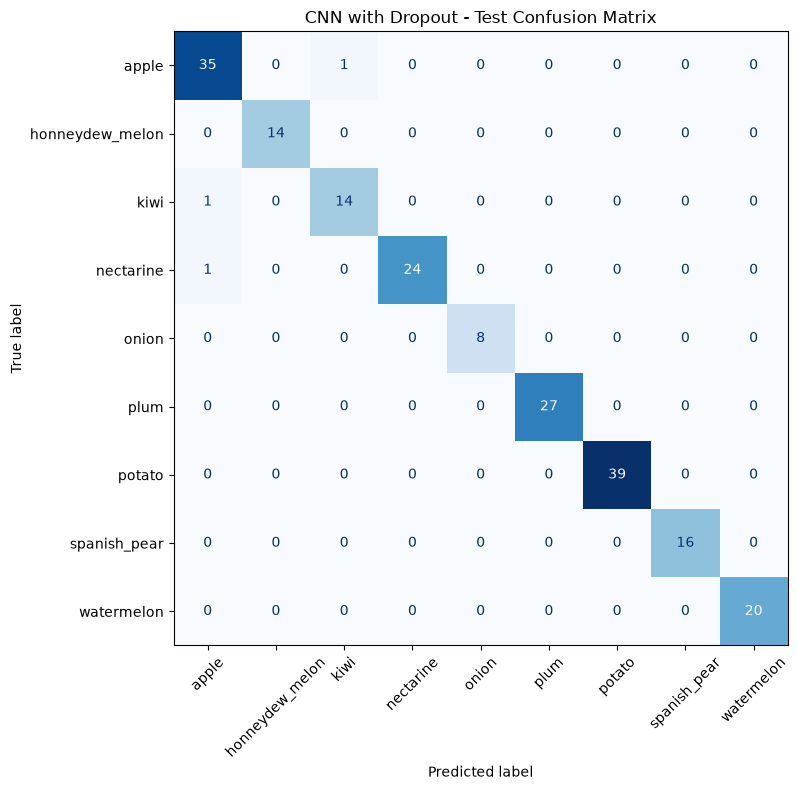

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix for the test dataset
test_cm = confusion_matrix(
    test_y_true,
    test_y_pred,
    labels=range(len(class_names))
)

# Create the confusion matrix visualization
fig, ax = plt.subplots(figsize=(10, 8))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=class_names
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN with Dropout - Test Confusion Matrix")

plt.tight_layout()
plt.show()

#### 3.9.3 Compare CNN with Baseline

We compare our CNN with dropout to the logistic regression baseline using the same 200 test images.

The logistic regression model uses color histograms, while the CNN learns patterns directly from the images.

We compare test accuracy and macro F1-score to see how much the CNN improves classification performance.

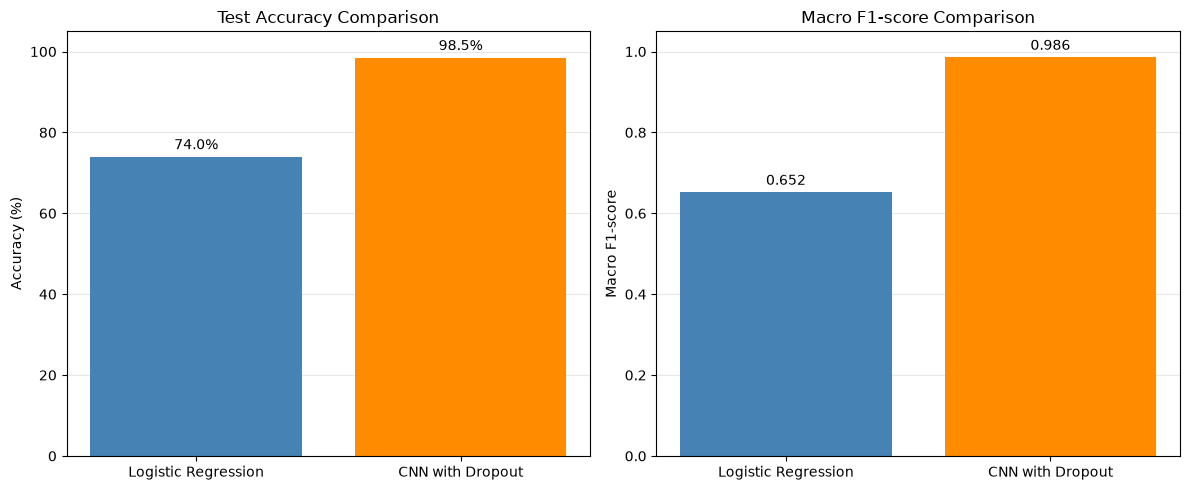

In [33]:
from sklearn.metrics import f1_score

# Baseline results from the logistic regression evaluation
baseline_accuracy = 0.74
baseline_macro_f1 = 0.652

# Calculate CNN results on the test dataset
cnn_accuracy = accuracy_score(test_y_true, test_y_pred)
cnn_macro_f1 = f1_score(
    test_y_true,
    test_y_pred,
    average="macro"
)

# Prepare model comparison
models = ["Logistic Regression", "CNN with Dropout"]

accuracy_values = [
    baseline_accuracy * 100,
    cnn_accuracy * 100
]

f1_values = [
    baseline_macro_f1,
    cnn_macro_f1
]

# Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare test accuracy
bars_accuracy = axes[0].bar(
    models,
    accuracy_values,
    color=["steelblue", "darkorange"]
)

axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 105)
axes[0].bar_label(bars_accuracy, fmt="%.1f%%", padding=3)

# Compare macro F1-score
bars_f1 = axes[1].bar(
    models,
    f1_values,
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Macro F1-score Comparison")
axes[1].set_ylabel("Macro F1-score")
axes[1].set_ylim(0, 1.05)
axes[1].bar_label(bars_f1, fmt="%.3f", padding=3)

# Apply consistent formatting
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 3.9.4 Analysis of Test Results

The results show that our CNN with dropout performs much better than the logistic regression baseline.

**Accuracy:** The logistic regression model correctly classifies 74% of the test images, while our CNN achieves 98.5%. This means that our CNN correctly classifies 197 out of 200 images, compared to 148 for logistic regression.

**Macro F1-score:** This measures how well the models perform across all nine classes, giving each class equal importance. The CNN achieves 0.986 compared to 0.652 for logistic regression. This shows that the CNN performs better across the different fruit and vegetable classes.

**Confusion matrix:** Our CNN makes only three mistakes. It confuses one apple with kiwi, one kiwi with apple, and one nectarine with apple. All other test images are classified correctly.

**Conclusion:** The CNN is clearly the better model on our test dataset. It can learn patterns directly from the images, while logistic regression uses simpler color-based features. This may explain why the CNN performs better.

The results are very good, but we have only tested the model on 200 images. We cannot be certain that it will perform equally well on completely new images outside our dataset.

#### 3.9.5 Visualize CNN Feature Maps

To better understand how our CNN processes images, we visualize the feature maps from its first convolutional layer.

The CNN uses learned filters to detect different visual patterns in an image. Each feature map shows which parts of the image activate a particular filter.

This helps us understand how the CNN extracts information from images before making a classification.

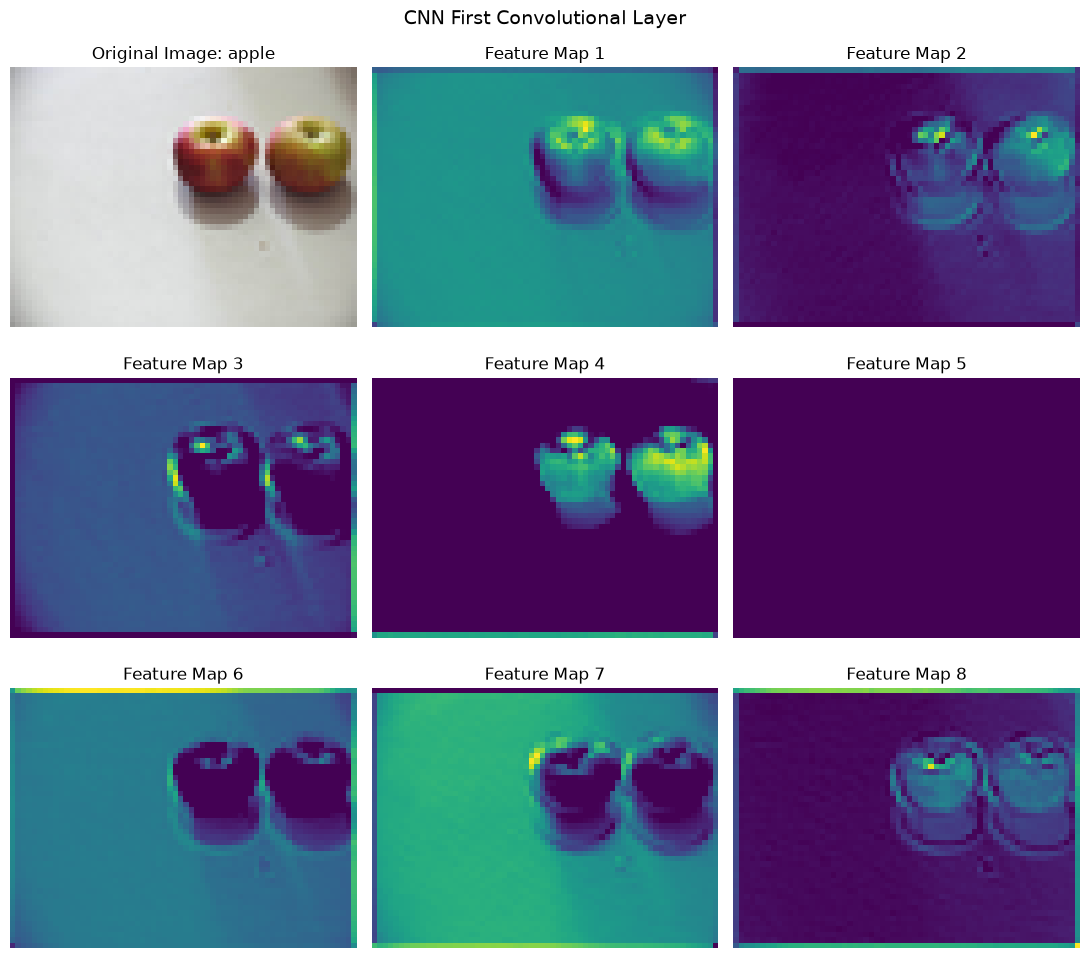

In [35]:
# Select an image from the training dataset
image, label = train_dataset[0]

# Prepare the image for the CNN
input_image = image.unsqueeze(0).to(device)

# Extract feature maps from the first convolutional layer
final_model.eval()

with torch.no_grad():
    first_conv = final_model.features[0]
    feature_maps = torch.relu(first_conv(input_image))

# Convert feature maps to NumPy
feature_maps = feature_maps.squeeze(0).cpu().numpy()

# Display the original image and eight feature maps
fig, axes = plt.subplots(3, 3, figsize=(11, 10))

axes[0, 0].imshow(image.permute(1, 2, 0).cpu().numpy())
axes[0, 0].set_title(f"Original Image: {class_names[label.item()]}")
axes[0, 0].axis("off")

# Display eight feature maps
for i, ax in enumerate(axes.flat[1:]):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

plt.suptitle("CNN First Convolutional Layer", fontsize=14)
plt.tight_layout()
plt.show()

#### Analysis of CNN Feature Maps

The feature maps show how different filters react to the same image of two apples.

Some filters highlight the edges and shapes of the apples, while others respond to different visual patterns. Some feature maps are almost completely dark, meaning that those filters have little or no activation for this image.

This shows that the CNN extracts different types of information from the image before making its prediction.

Unlike logistic regression, which uses color histograms, our CNN can learn visual patterns directly from the images.

### 3.10 Conclusions and Documentation

In this project, we trained a Convolutional Neural Network (CNN) to classify images into nine different fruit and vegetable classes.

We first trained a CNN without dropout and then created a second model with dropout to see if it could improve performance.

**Model comparison**

Both CNN models performed well on the validation dataset. The original CNN achieved 94% accuracy, while the CNN with dropout achieved 95%.

The original model had slightly lower validation loss, but the dropout model correctly classified two more images. We therefore selected the dropout model for final testing.

**Final test results**

Our selected CNN achieved:

- **98.5% test accuracy** – 197 out of 200 images classified correctly.
- **0.986 macro F1-score** – strong performance across all nine classes.

The model only made three mistakes, confusing apple with kiwi, kiwi with apple, and nectarine with apple.

**Comparison with Logistic Regression**

The logistic regression baseline achieved 74% test accuracy and a macro F1-score of 0.652.

Our CNN performed significantly better on the same test images. This suggests that learning features directly from images works better for this task than using color histograms alone.

**Limitations and possible improvements**

Our test dataset contains only 200 images, so we cannot be certain that the model will perform equally well on completely new images.

In the future, we could improve the project by using more images, testing data augmentation or experimenting with different CNN architectures.

**Conclusion**

Our CNN successfully learned to recognize the nine fruit and vegetable classes and achieved high accuracy on unseen test images.

The results show that CNN is an effective method for image classification in our dataset.